# Vehicle Image Classification: EfficientNetB0 (end to end)

Three classes: **airplanes / cars / ship**.

Pipeline: load -> clean -> EDA -> split -> tf.data + augmentation -> EfficientNetB0 transfer
learning -> fine-tune -> evaluate -> Grad-CAM -> save + single-image inference.

**Note on the dataset:** there are only 48 images (16 per class), so the accuracy numbers here
are estimates from a 9-image test set and should not be read as a reliable score. The 5-fold
cross-validation cell near the end gives a steadier number. Two known data issues are flagged
in the EDA section.

## 1. Setup

In [1]:
import os, glob, hashlib, json, zipfile, random, shutil
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve, auc)
from sklearn.preprocessing import label_binarize

SEED    = 42
IMG_SIZE = 224          # EfficientNetB0's native input size
BATCH   = 8
AUTOTUNE = tf.data.AUTOTUNE

random.seed(SEED); np.random.seed(SEED)
tf.random.set_seed(SEED); keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: []


## 2. Load the data

If you are on Colab, upload `vehicles.zip` first (the file-upload cell below), or point
`DATA_ROOT` at a folder you already have. The expected layout is one subfolder per class:

```
vehicles/
  airplanes/*.jpg
  cars/*.jpg
  ship/*.jpg
```

In [2]:
ZIP_PATH  = "vehicles.zip"      # change if your zip lives elsewhere
EXTRACT_TO = "."
DATA_ROOT = "vehicles"          # folder containing one subfolder per class

# --- Colab upload helper: uncomment if you need to upload the zip interactively ---
# from google.colab import files
# uploaded = files.upload()
# ZIP_PATH = list(uploaded.keys())[0]

if not os.path.isdir(DATA_ROOT) and os.path.exists(ZIP_PATH):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_TO)
    print("extracted", ZIP_PATH)

assert os.path.isdir(DATA_ROOT), f"{DATA_ROOT} not found. Upload the zip or fix DATA_ROOT."

CLASS_NAMES = sorted(d for d in os.listdir(DATA_ROOT)
                     if os.path.isdir(os.path.join(DATA_ROOT, d)))
NUM_CLASSES = len(CLASS_NAMES)
print("classes:", CLASS_NAMES)
for c in CLASS_NAMES:
    print(f"  {c:12s} {len(os.listdir(os.path.join(DATA_ROOT, c))):4d} files")

classes: ['airplanes', 'cars', 'ship']
  airplanes      16 files
  cars           16 files
  ship           16 files


## 3. Cleaning

Four checks, each of which silently poisons training if skipped:

1. **Corrupt / truncated files** - `PIL.verify()` catches these before they reach `tf.data`.
2. **Exact duplicates** - MD5 hash. A duplicate that lands in both train and test leaks the label.
3. **Non-RGB modes** - grayscale or RGBA images break a 3-channel input; everything is
   converted to RGB.
4. **Degenerate images** - anything smaller than 32px on a side is dropped.

In [3]:
records, seen_hashes = [], {}
n_corrupt = n_dup = n_tiny = 0

for ci, cls in enumerate(CLASS_NAMES):
    for path in sorted(glob.glob(os.path.join(DATA_ROOT, cls, "*"))):
        # 1. corrupt check
        try:
            Image.open(path).verify()
            im = Image.open(path)
            w, h = im.size
        except Exception as e:
            print(f"  corrupt, dropped: {path} ({e})"); n_corrupt += 1; continue

        # 4. degenerate check
        if w < 32 or h < 32:
            print(f"  too small, dropped: {path} ({w}x{h})"); n_tiny += 1; continue

        # 2. duplicate check
        digest = hashlib.md5(open(path, "rb").read()).hexdigest()
        if digest in seen_hashes:
            print(f"  duplicate of {os.path.basename(seen_hashes[digest])}, dropped: {path}")
            n_dup += 1; continue
        seen_hashes[digest] = path

        # 3. mode normalisation happens at load time via .convert("RGB")
        arr = np.asarray(im.convert("RGB"))
        records.append(dict(path=path, cls=cls, label=ci, width=w, height=h,
                            mode=im.mode, aspect=w / h,
                            kb=os.path.getsize(path) / 1024,
                            mean_px=float(arr.mean()), std_px=float(arr.std())))

df = pd.DataFrame(records)
print(f"\nkept {len(df)} images | dropped: {n_corrupt} corrupt, {n_dup} duplicate, {n_tiny} tiny")
df.head()


kept 48 images | dropped: 0 corrupt, 0 duplicate, 0 tiny


,path,cls,label,width,height,mode,aspect,kb,mean_px,std_px
0,vehicles\airplanes\airplane937.jpg,airplanes,0,1200,1200,RGB,1.0,100.525391,121.102545,48.272025
1,vehicles\airplanes\airplane938.jpg,airplanes,0,1200,1200,RGB,1.0,83.518555,120.125432,52.776925
2,vehicles\airplanes\airplane939.jpg,airplanes,0,1200,1200,RGB,1.0,31.551758,96.852399,46.524238
3,vehicles\airplanes\airplane94.jpg,airplanes,0,1200,1200,RGB,1.0,73.324219,175.676736,39.280886
4,vehicles\airplanes\airplane940.jpg,airplanes,0,1200,1200,RGB,1.0,63.418945,110.385744,56.576269


## 4. Exploratory data analysis

In [4]:
print("class balance")
print(df["cls"].value_counts().to_string())
print("\ncolour modes:", df["mode"].value_counts().to_dict())
print("\nnumeric summary")
display(df.groupby("cls")[["width", "height", "aspect", "kb", "mean_px", "std_px"]]
          .agg(["mean", "min", "max"]).round(1))

class balance
cls
airplanes    16
cars         16
ship         16

colour modes: {'RGB': 48}

numeric summary


width              height             aspect               kb  \
             mean   min   max    mean   min   max   mean  min  max   mean   
cls                                                                         
airplanes  1200.0  1200  1200  1200.0  1200  1200    1.0  1.0  1.0   99.5   
cars       1200.0  1200  1200  1200.0  1200  1200    1.0  1.0  1.0  136.6   
ship        210.0   210   210   143.9   118   158    1.5  1.3  1.8    9.9   

                       mean_px              std_px               
            min    max    mean   min    max   mean   min    max  
cls                                                              
airplanes  31.6  245.4   136.3  49.5  192.7   52.8  36.0   88.7  
cars       79.4  261.1    99.3  42.4  157.1   71.8  56.2  102.7  
ship        6.1   15.9   138.1  84.4  190.0   62.2  32.7   82.1

C:\Users\MSI MODERN\AppData\Local\Temp\ipykernel_28180\3257552835.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="cls", order=CLASS_NAMES, ax=ax[0, 0], palette="deep")
C:\Users\MSI MODERN\AppData\Local\Temp\ipykernel_28180\3257552835.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="cls", y="kb", order=CLASS_NAMES, ax=ax[1, 1], palette="deep")


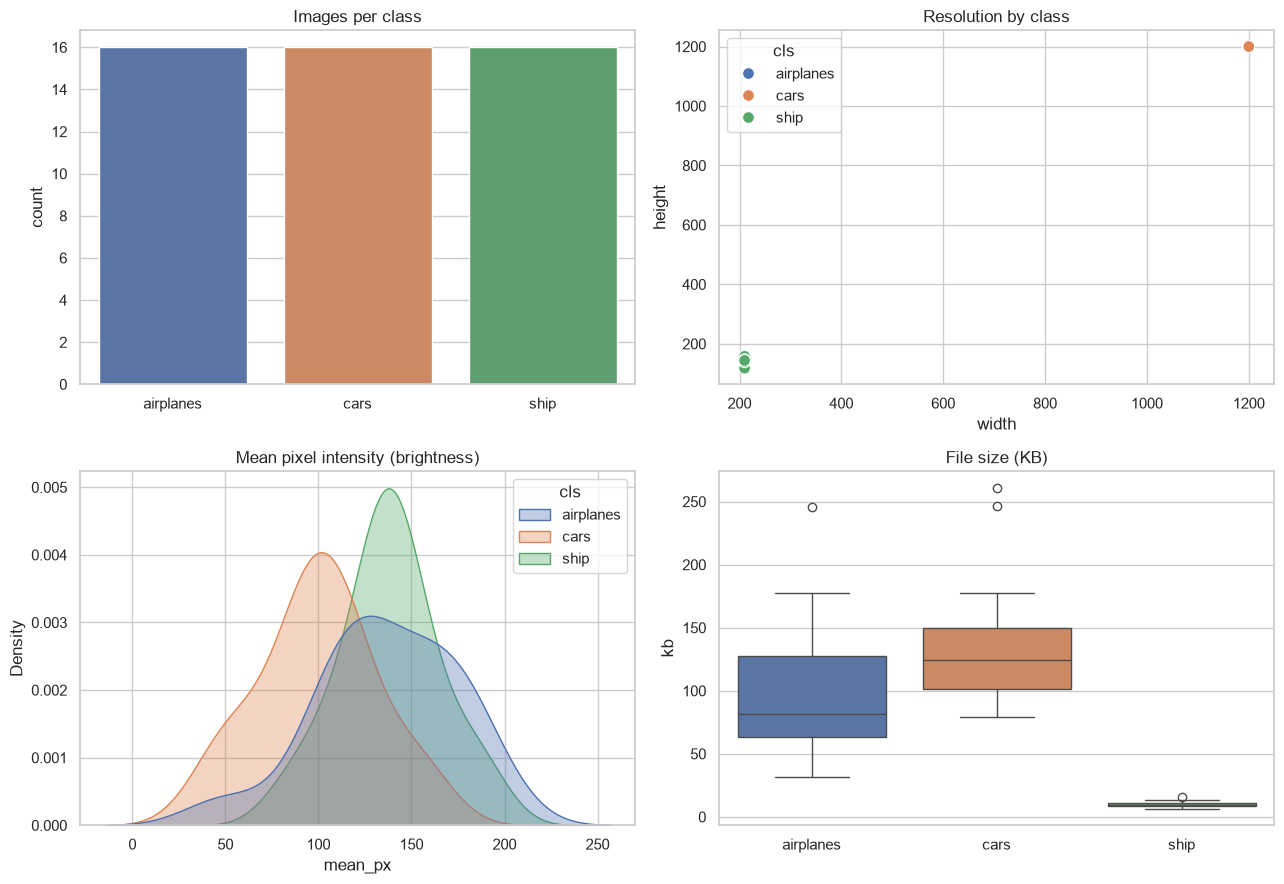

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

sns.countplot(data=df, x="cls", order=CLASS_NAMES, ax=ax[0, 0], palette="deep")
ax[0, 0].set_title("Images per class"); ax[0, 0].set_xlabel("")

sns.scatterplot(data=df, x="width", y="height", hue="cls", s=70, ax=ax[0, 1])
ax[0, 1].set_title("Resolution by class")

sns.kdeplot(data=df, x="mean_px", hue="cls", fill=True, alpha=.35, ax=ax[1, 0])
ax[1, 0].set_title("Mean pixel intensity (brightness)")

sns.boxplot(data=df, x="cls", y="kb", order=CLASS_NAMES, ax=ax[1, 1], palette="deep")
ax[1, 1].set_title("File size (KB)"); ax[1, 1].set_xlabel("")

plt.tight_layout(); plt.show()

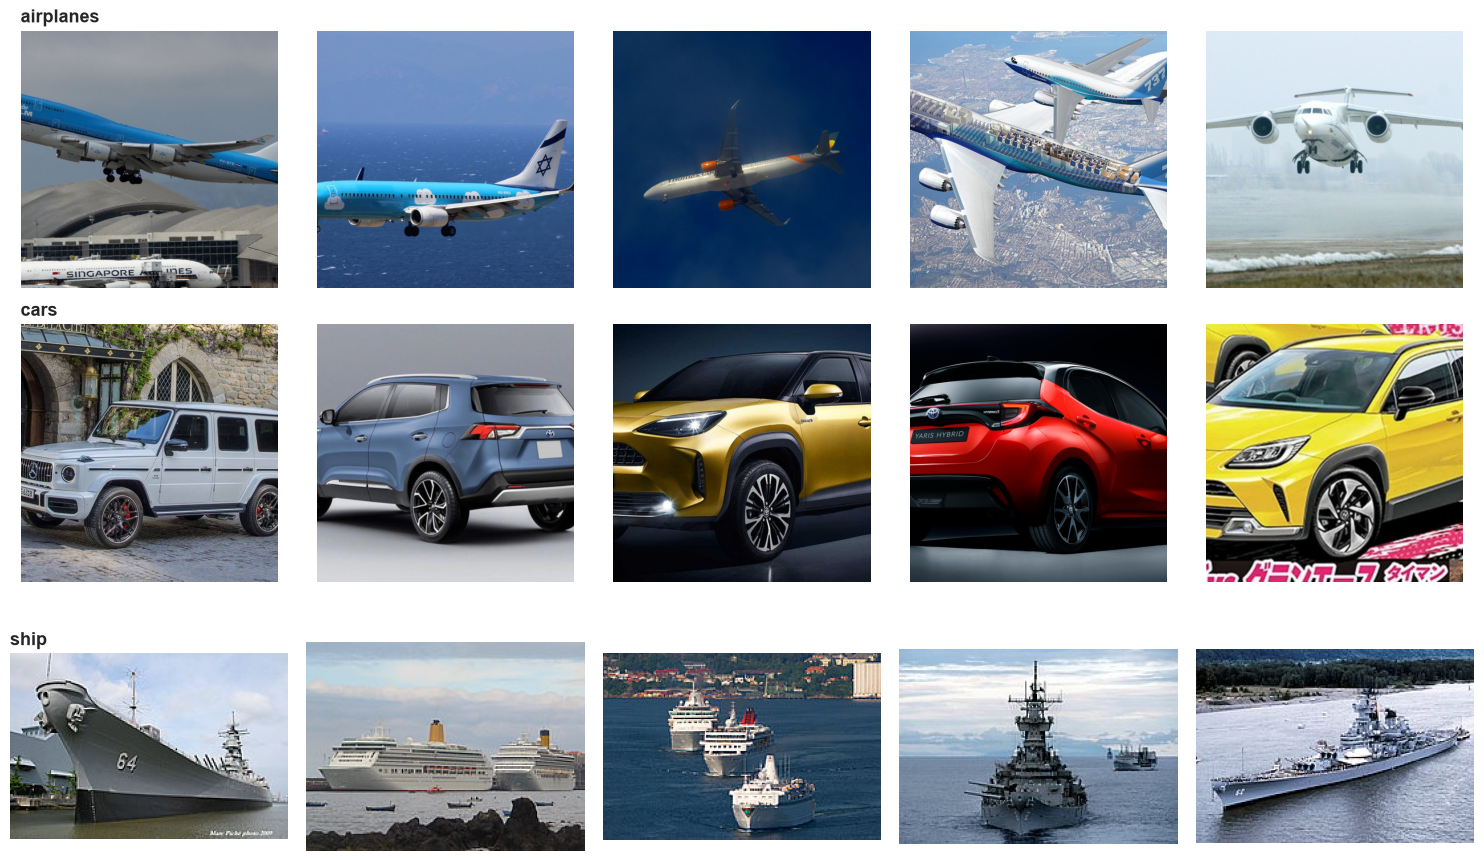

In [6]:
# sample grid: 5 random images per class
N_SHOW = 5
fig, axes = plt.subplots(NUM_CLASSES, N_SHOW, figsize=(3 * N_SHOW, 3 * NUM_CLASSES))
axes = np.atleast_2d(axes)
for i, cls in enumerate(CLASS_NAMES):
    sub = df[df.cls == cls].sample(min(N_SHOW, (df.cls == cls).sum()), random_state=SEED)
    for j, (_, r) in enumerate(sub.iterrows()):
        axes[i, j].imshow(Image.open(r.path).convert("RGB")); axes[i, j].axis("off")
    axes[i, 0].set_title(cls, loc="left", fontsize=13, fontweight="bold")
    for j in range(len(sub), N_SHOW):
        axes[i, j].axis("off")
plt.tight_layout(); plt.show()

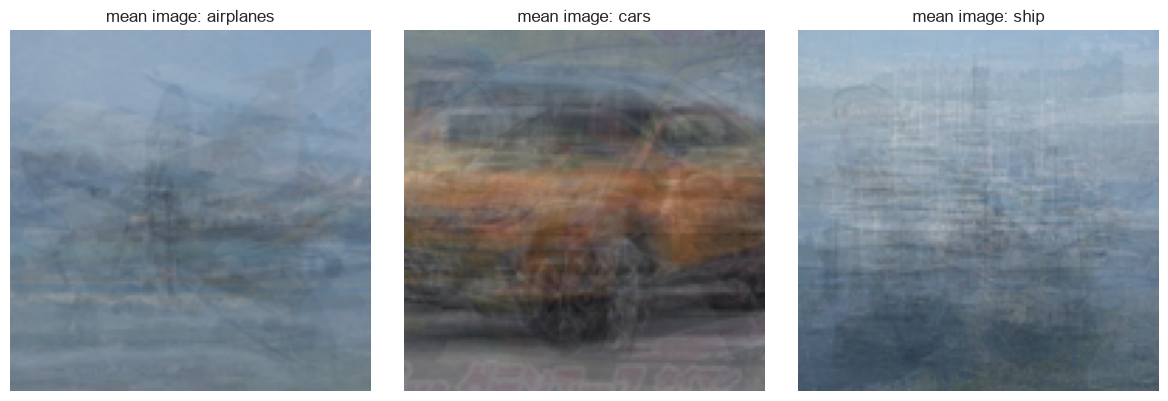

In [7]:
# average image per class: shows what the model sees before it sees any detail
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(4 * NUM_CLASSES, 4))
axes = np.atleast_1d(axes)
for i, cls in enumerate(CLASS_NAMES):
    stack = np.stack([
        np.asarray(Image.open(p).convert("RGB").resize((128, 128)), dtype="float32")
        for p in df[df.cls == cls].path
    ])
    axes[i].imshow(stack.mean(0).astype("uint8")); axes[i].axis("off")
    axes[i].set_title(f"mean image: {cls}")
plt.tight_layout(); plt.show()

### EDA findings

Two things in this dataset are worth acting on before you trust any score:

**1. Resolution is a giveaway.** All airplane and car images are exactly 1200x1200. All ship
images are 210 wide and 118-158 tall, roughly 10 KB each versus 100-137 KB for the other two
classes. Ships clearly came from a different source. After resizing to 224x224 the ship images
carry visible upscaling blur that the other classes do not, so a model can learn *"blurry means
ship"* rather than learning what a ship looks like. That shortcut will not survive contact with
new data. Fix: source all three classes at comparable resolution.

**2. The dataset is tiny.** 16 images per class leaves about 10 per class for training. Transfer
learning makes this workable (the backbone already knows edges, textures and shapes from
ImageNet), but the test set is 9 images, so a single misclassification moves accuracy by 11
points. Treat the cross-validation number as the real estimate.

## 5. Stratified train / validation / test split

Stratifying keeps all three classes proportionally represented in each split, which matters
enormously when each split only holds a handful of images.

In [8]:
paths  = df["path"].values
labels = df["label"].values

p_train, p_tmp, y_train, y_tmp = train_test_split(
    paths, labels, test_size=0.375, stratify=labels, random_state=SEED)
p_val, p_test, y_val, y_test = train_test_split(
    p_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)

for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:6s} n={len(y):3d}  per class: "
          f"{dict(zip(CLASS_NAMES, np.bincount(y, minlength=NUM_CLASSES)))}")

train  n= 30  per class: {'airplanes': np.int64(10), 'cars': np.int64(10), 'ship': np.int64(10)}
val    n=  9  per class: {'airplanes': np.int64(3), 'cars': np.int64(3), 'ship': np.int64(3)}
test   n=  9  per class: {'airplanes': np.int64(3), 'cars': np.int64(3), 'ship': np.int64(3)}


## 6. Preprocessing and `tf.data` input pipeline

**EfficientNet-specific detail worth knowing:** `keras.applications.EfficientNetB0` has
normalisation baked into the model graph. It expects pixels in the **0-255** range. Do *not*
add a `Rescaling(1./255)` layer in front of it, which is the single most common mistake with
this backbone and quietly costs you most of your accuracy.

Augmentation runs only on the training set, and only during training (`training=True`).

In [9]:
def decode(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32)           # stays in 0-255 for EfficientNet
    return img, label

def make_ds(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(p_train, y_train, shuffle=True)
val_ds   = make_ds(p_val,   y_val)
test_ds  = make_ds(p_test,  y_test)

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomContrast(0.15),
], name="data_augmentation")

xb, yb = next(iter(train_ds))
print("batch:", xb.shape, xb.dtype, "| pixel range:",
      float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)))

batch: (8, 224, 224, 3) <dtype: 'float32'> | pixel range: 0.0 - 255.0


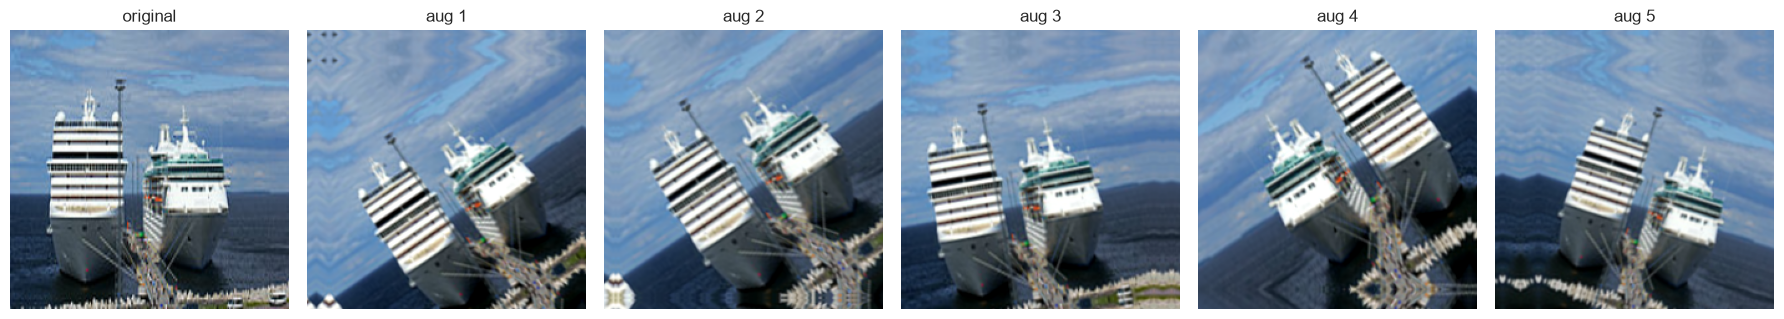

In [10]:
# what augmentation actually does to one image
img = xb[0:1]
fig, axes = plt.subplots(1, 6, figsize=(18, 3.2))
axes[0].imshow(tf.cast(img[0], tf.uint8)); axes[0].set_title("original"); axes[0].axis("off")
for i in range(1, 6):
    aug = data_augmentation(img, training=True)
    axes[i].imshow(tf.cast(tf.clip_by_value(aug[0], 0, 255), tf.uint8))
    axes[i].set_title(f"aug {i}"); axes[i].axis("off")
plt.tight_layout(); plt.show()

## 7. Model: EfficientNetB0 transfer learning

Stage 1 freezes the entire ImageNet backbone and trains only a small classification head. With
30 training images, training the 4M backbone parameters from the start would overfit instantly.

In [11]:
def build_model(num_classes=NUM_CLASSES, dropout=0.3):
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation(inputs)

    base = keras.applications.EfficientNetB0(
        include_top=False,        # drop the 1000-class ImageNet head
        weights="imagenet",
        input_tensor=x,
    )
    base.trainable = False        # stage 1: frozen backbone

    x = layers.GlobalAveragePooling2D(name="gap")(base.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout, name="head_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)

    model = keras.Model(inputs, outputs, name="efficientnetb0_vehicles")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model, base

model, base_model = build_model()
print(f"total params      {model.count_params():,}")
print(f"trainable params  {sum(np.prod(w.shape) for w in model.trainable_weights):,}")
model.summary(show_trainable=True)

       0/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   24576/16705208 ━━━━━━━━━━━━━━━━━━━━ 1:00 4us/step

   49152/16705208 ━━━━━━━━━━━━━━━━━━━━ 48s 3us/step 

   81920/16705208 ━━━━━━━━━━━━━━━━━━━━ 42s 3us/step

  122880/16705208 ━━━━━━━━━━━━━━━━━━━━ 36s 2us/step

...

Model: "efficientnetb0_vehicles"

┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)      ┃ Output Shape    ┃   Param # ┃ Connected to   ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1     │ (None, 224,     │         0 │ -              │   -   │
│ (InputLayer)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ data_augmentation │ (None, 224,     │         0 │ input_layer_1… │   -   │
│ (Sequential)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ rescaling         │ (None, 224,     │         0 │ data_augmenta… │   -   │
│ (Rescaling)       │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ normalization     │ (None, 224,     │         7 │ rescaling[0][… │   N   │
│ (Normalization)   │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ rescaling_1       │ (None, 224,     │         0 │ normalization… │   -   │
│ (Rescaling)       │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ stem_conv_pad     │ (None, 225,     │         0 │ rescaling_1[0… │   -   │
│ (ZeroPadding2D)   │ 225, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ stem_conv         │ (None, 112,     │       864 │ stem_conv_pad… │   N   │
│ (Conv2D)          │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ stem_bn           │ (None, 112,     │       128 │ stem_conv[0][… │   N   │
│ (BatchNormalizat… │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ stem_activation   │ (None, 112,     │         0 │ stem_bn[0][0]  │   -   │
│ (Activation)      │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_dwconv    │ (None, 112,     │       288 │ stem_activati… │   N   │
│ (DepthwiseConv2D) │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_bn        │ (None, 112,     │       128 │ block1a_dwcon… │   N   │
│ (BatchNormalizat… │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_activati… │ (None, 112,     │         0 │ block1a_bn[0]… │   -   │
│ (Activation)      │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_se_squee… │ (None, 32)      │         0 │ block1a_activ… │   -   │
│ (GlobalAveragePo… │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_se_resha… │ (None, 1, 1,    │         0 │ block1a_se_sq… │   -   │
│ (Reshape)         │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_se_reduce │ (None, 1, 1, 8) │       264 │ block1a_se_re… │   N   │
│ (Conv2D)          │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_se_expand │ (None, 1, 1,    │       288 │ block1a_se_re… │   N   │
│ (Conv2D)          │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_se_excite │ (None, 112,     │         0 │ block1a_activ… │   - 

 Total params: 4,058,534 (15.48 MB)

 Trainable params: 6,403 (25.01 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [12]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=12,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=5, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint("best_head.keras", monitor="val_accuracy",
                                    save_best_only=True, verbose=0),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=40,
                    callbacks=callbacks, verbose=1)

Epoch 1/40


C:\Users\MSI MODERN\miniconda3\envs\myenv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1/4 ━━━━━━━━━━━━━━━━━━━━ 46s 16s/step - accuracy: 0.6250 - loss: 0.8550

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step - accuracy: 0.6250 - loss: 1.0265

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step - accuracy: 0.7083 - loss: 0.7683

...

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 1.0000 - loss: 5.2113e-04

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step - accuracy: 1.0000 - loss: 6.8296e-04

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step - accuracy: 1.0000 - loss: 5.6176e-04

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 343ms/step - accuracy: 1.0000 - loss: 5.6176e-04 - val_accuracy: 1.0000 - val_loss: 0.0480 - learning_rate: 0.0010


Restoring model weights from the end of the best epoch: 40.


### Stage 2: fine-tuning

Unfreeze the top block of the backbone and continue at a much lower learning rate. The
`BatchNormalization` layers stay frozen on purpose: with a batch size of 8, recomputing batch
statistics destabilises the pretrained features.

In [13]:
base_model.trainable = True

# freeze everything except the last 20 layers, and keep all BatchNorm frozen
for layer in base_model.layers[:-20]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),   # 100x lower than stage 1
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print(f"trainable params now {sum(np.prod(w.shape) for w in model.trainable_weights):,}")

history_ft = model.fit(
    train_ds, validation_data=val_ds, epochs=20,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ModelCheckpoint("best_finetuned.keras", monitor="val_accuracy",
                                        save_best_only=True, verbose=0),
    ],
    verbose=1,
)

trainable params now 1,349,171
Epoch 1/20


1/4 ━━━━━━━━━━━━━━━━━━━━ 57s 19s/step - accuracy: 1.0000 - loss: 1.5313e-04

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step - accuracy: 1.0000 - loss: 0.0152   

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 279ms/step - accuracy: 1.0000 - loss: 0.0149

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step - accuracy: 1.0000 - loss: 0.0138

...

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 263ms/step - accuracy: 1.0000 - loss: 8.8275e-04

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step - accuracy: 1.0000 - loss: 7.7983e-04

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step - accuracy: 1.0000 - loss: 0.0017    

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 369ms/step - accuracy: 1.0000 - loss: 0.0017 - val_accuracy: 1.0000 - val_loss: 0.0271


Restoring model weights from the end of the best epoch: 20.


## 8. Evaluation

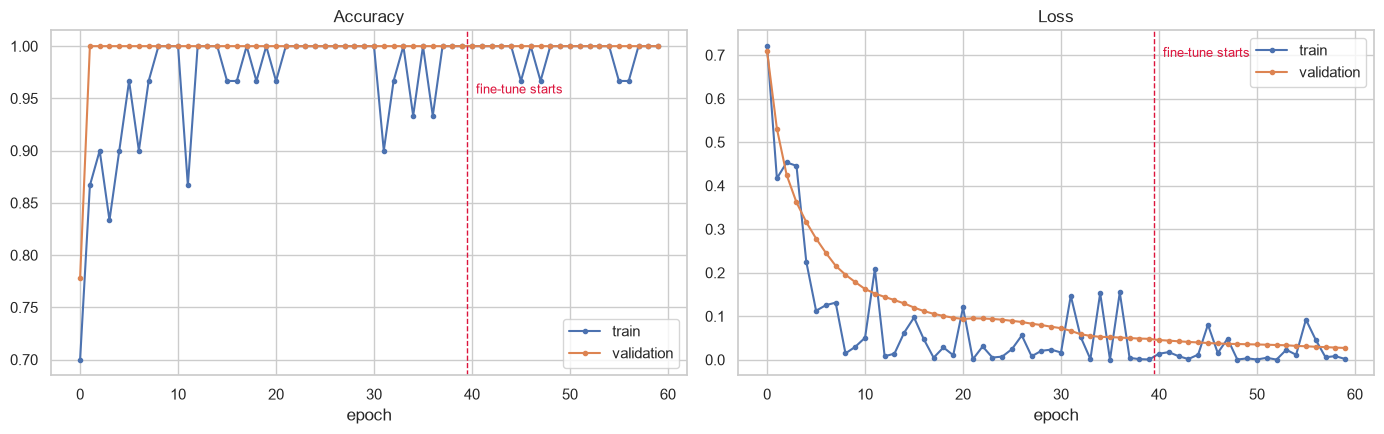

In [14]:
def merge(h1, h2, key):
    return list(h1.history.get(key, [])) + list(h2.history.get(key, []))

split_at = len(history.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for i, (k, vk, title) in enumerate([("accuracy", "val_accuracy", "Accuracy"),
                                    ("loss", "val_loss", "Loss")]):
    ax[i].plot(merge(history, history_ft, k),  marker="o", ms=3, label="train")
    ax[i].plot(merge(history, history_ft, vk), marker="o", ms=3, label="validation")
    ax[i].axvline(split_at - 0.5, color="crimson", ls="--", lw=1)
    ax[i].text(split_at, ax[i].get_ylim()[1] * 0.95, " fine-tune starts",
               color="crimson", fontsize=9, va="top")
    ax[i].set_title(title); ax[i].set_xlabel("epoch"); ax[i].legend()
plt.tight_layout(); plt.show()

In [15]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
y_proba = model.predict(test_ds, verbose=0)
y_pred  = y_proba.argmax(axis=1)
y_true  = np.concatenate([y.numpy() for _, y in test_ds])

print(f"Test loss     {test_loss:.4f}")
print(f"Test accuracy {test_acc:.4f}   ({(y_pred == y_true).sum()}/{len(y_true)} correct)")
print("\n" + classification_report(y_true, y_pred, target_names=CLASS_NAMES,
                                    digits=3, zero_division=0))

Test loss     0.0019
Test accuracy 1.0000   (9/9 correct)

              precision    recall  f1-score   support

   airplanes      1.000     1.000     1.000         3
        cars      1.000     1.000     1.000         3
        ship      1.000     1.000     1.000         3

    accuracy                          1.000         9
   macro avg      1.000     1.000     1.000         9
weighted avg      1.000     1.000     1.000         9



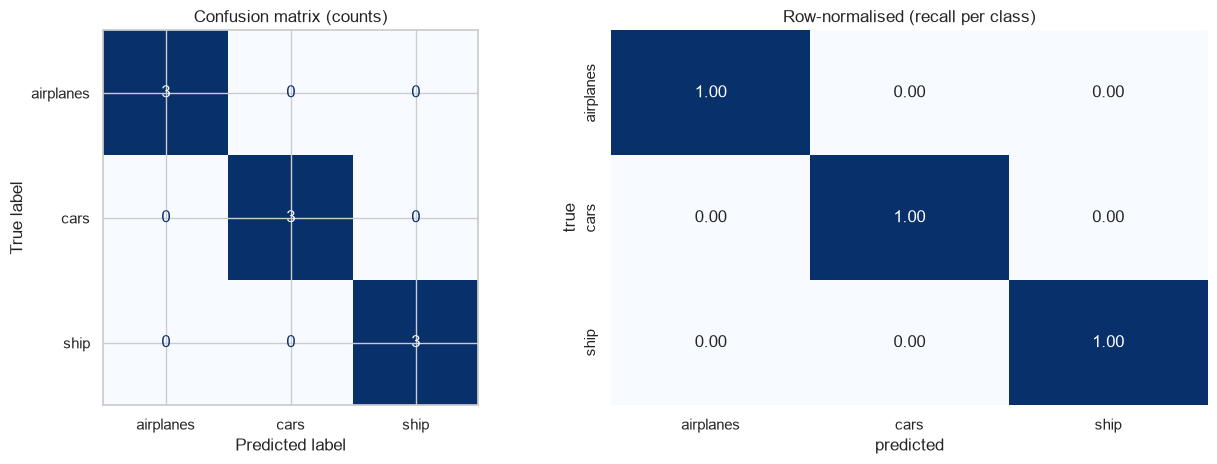

In [16]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ax[0].set_title("Confusion matrix (counts)")

cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1], vmin=0, vmax=1)
ax[1].set_title("Row-normalised (recall per class)")
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true")
plt.tight_layout(); plt.show()

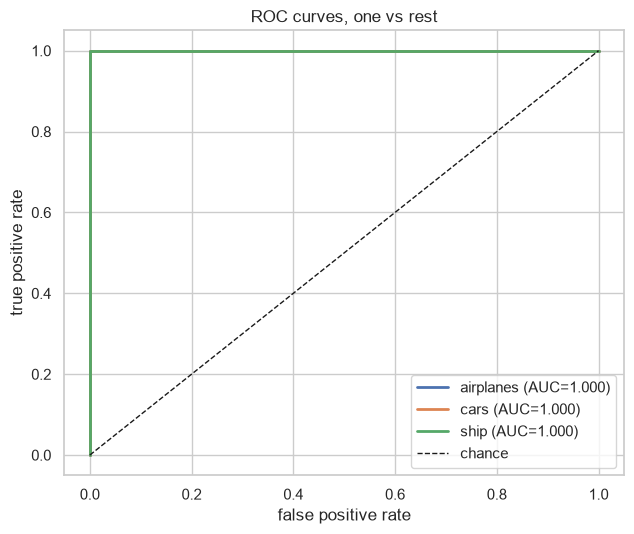

macro ROC-AUC: 1.0


In [17]:
# one-vs-rest ROC curves
y_bin = label_binarize(y_true, classes=range(NUM_CLASSES))
plt.figure(figsize=(6.5, 5.5))
for i, cls in enumerate(CLASS_NAMES):
    if y_bin[:, i].sum() == 0:
        continue
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba[:, i])
    plt.plot(fpr, tpr, lw=2, label=f"{cls} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="chance")
plt.xlabel("false positive rate"); plt.ylabel("true positive rate")
plt.title("ROC curves, one vs rest"); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

try:
    print("macro ROC-AUC:", round(roc_auc_score(y_true, y_proba, multi_class="ovr",
                                                average="macro"), 4))
except ValueError as e:
    print("macro ROC-AUC unavailable (a class is missing from the test split):", e)

In [18]:
# per-image prediction table, most-uncertain first
test_imgs = np.concatenate([x.numpy() for x, _ in test_ds])
pred_df = pd.DataFrame({
    "true":       [CLASS_NAMES[i] for i in y_true],
    "predicted":  [CLASS_NAMES[i] for i in y_pred],
    "confidence": y_proba.max(axis=1).round(3),
    "correct":    y_pred == y_true,
})
for i, c in enumerate(CLASS_NAMES):
    pred_df[f"p_{c}"] = y_proba[:, i].round(3)
display(pred_df.sort_values("confidence"))

,true,predicted,confidence,correct,p_airplanes,p_cars,p_ship
1,airplanes,airplanes,0.995,True,0.995,0.002,0.003
7,ship,ship,0.995,True,0.005,0.000,0.995
5,cars,cars,0.997,True,0.002,0.997,0.001
4,airplanes,airplanes,0.998,True,0.998,0.000,0.002
3,ship,ship,0.999,True,0.001,0.000,0.999
8,airplanes,airplanes,0.999,True,0.999,0.000,0.001
2,ship,ship,1.000,True,0.000,0.000,1.000
0,cars,cars,1.000,True,0.000,1.000,0.000
6,cars,cars,1.000,True,0.000,1.000,0.000


In [19]:
# misclassified images (if any)
wrong = np.where(y_pred != y_true)[0]
if len(wrong) == 0:
    print("No misclassifications on the test set.")
else:
    n = len(wrong)
    fig, axes = plt.subplots(1, n, figsize=(3.4 * n, 3.8), squeeze=False)
    for k, i in enumerate(wrong):
        axes[0][k].imshow(test_imgs[i].astype("uint8")); axes[0][k].axis("off")
        axes[0][k].set_title(f"true: {CLASS_NAMES[y_true[i]]}\n"
                             f"pred: {CLASS_NAMES[y_pred[i]]} ({y_proba[i].max():.2f})",
                             fontsize=10, color="crimson")
    plt.suptitle(f"{n} misclassified", y=1.03)
    plt.tight_layout(); plt.show()

No misclassifications on the test set.


## 9. Grad-CAM: what the model is actually looking at

This matters more than usual here. Given the resolution confound flagged in the EDA, Grad-CAM
tells you whether the model is attending to the *object* or to background and compression
artefacts. Heat on the hull, wings or wheels is a good sign; heat spread flatly over the sky or
water is a warning.

C:\Users\MSI MODERN\miniconda3\envs\myenv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_6']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


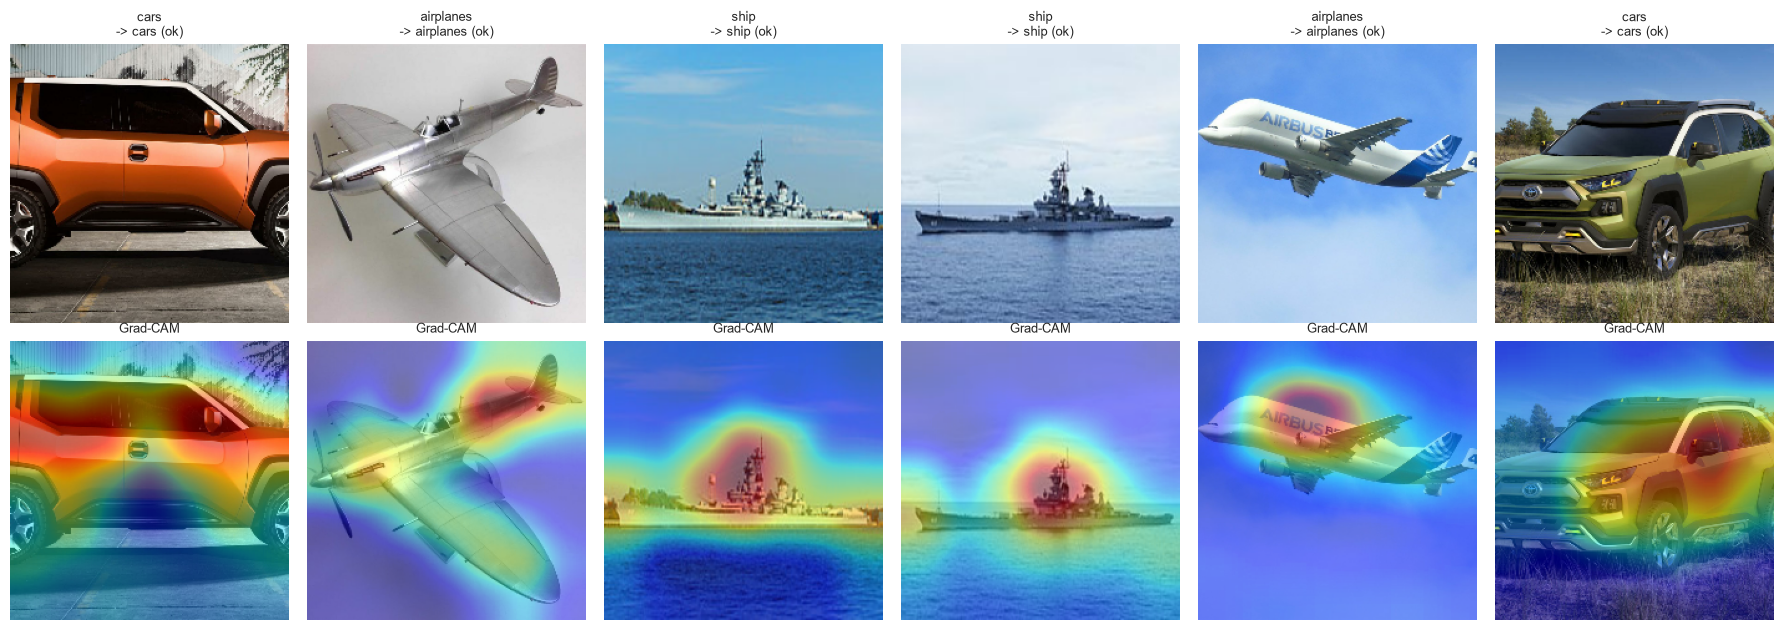

In [20]:
def gradcam_heatmap(img_array, model, last_conv_layer_name="top_conv", pred_index=None):
    grad_model = keras.Model(
        model.inputs,
        [model.get_layer(last_conv_layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_array, training=False)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]
    grads = tape.gradient(class_channel, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    heat = tf.squeeze(conv_out[0] @ pooled[..., tf.newaxis])
    heat = tf.maximum(heat, 0) / (tf.reduce_max(heat) + 1e-8)
    return heat.numpy()

n_show = min(6, len(test_imgs))
fig, axes = plt.subplots(2, n_show, figsize=(3 * n_show, 6.4))
axes = np.atleast_2d(axes)
for i in range(n_show):
    raw = test_imgs[i]
    heat = gradcam_heatmap(raw[None, ...], model)
    heat_rs = np.array(Image.fromarray(np.uint8(255 * heat)).resize((IMG_SIZE, IMG_SIZE)))
    ok = "ok" if y_pred[i] == y_true[i] else "WRONG"
    axes[0, i].imshow(raw.astype("uint8")); axes[0, i].axis("off")
    axes[0, i].set_title(f"{CLASS_NAMES[y_true[i]]}\n-> {CLASS_NAMES[y_pred[i]]} ({ok})",
                         fontsize=9)
    axes[1, i].imshow(raw.astype("uint8"))
    axes[1, i].imshow(heat_rs, cmap="jet", alpha=0.45); axes[1, i].axis("off")
    axes[1, i].set_title("Grad-CAM", fontsize=9)
plt.tight_layout(); plt.show()

## 10. 5-fold stratified cross-validation

With a 9-image test set, a single split tells you very little. Cross-validation reuses every
image as test data exactly once and reports mean and spread, which is the number to quote.

This retrains the model five times. On a Colab GPU expect a few minutes; on CPU, considerably
longer. Set `RUN_CV = False` to skip.

C:\Users\MSI MODERN\miniconda3\envs\myenv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


fold 1: accuracy 1.000  (n_test=10)


fold 2: accuracy 1.000  (n_test=10)


fold 3: accuracy 1.000  (n_test=10)


fold 4: accuracy 1.000  (n_test=9)


fold 5: accuracy 1.000  (n_test=9)

5-fold CV accuracy: 1.000 +/- 0.000


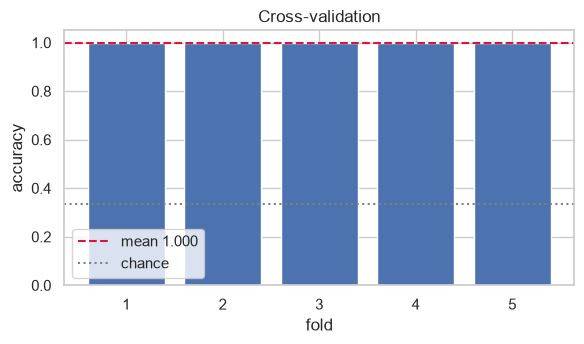

In [21]:
RUN_CV = True

if RUN_CV:
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    fold_scores = []
    for fold, (tr_idx, te_idx) in enumerate(skf.split(paths, labels), start=1):
        keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
        m, _ = build_model()
        m.fit(make_ds(paths[tr_idx], labels[tr_idx], shuffle=True),
              epochs=25, verbose=0)
        acc = m.evaluate(make_ds(paths[te_idx], labels[te_idx]), verbose=0)[1]
        fold_scores.append(acc)
        print(f"fold {fold}: accuracy {acc:.3f}  (n_test={len(te_idx)})")

    print(f"\n5-fold CV accuracy: {np.mean(fold_scores):.3f} "
          f"+/- {np.std(fold_scores):.3f}")

    plt.figure(figsize=(6, 3.6))
    plt.bar(range(1, 6), fold_scores, color="#4C72B0")
    plt.axhline(np.mean(fold_scores), color="crimson", ls="--",
                label=f"mean {np.mean(fold_scores):.3f}")
    plt.axhline(1 / NUM_CLASSES, color="gray", ls=":", label="chance")
    plt.ylim(0, 1.05); plt.xlabel("fold"); plt.ylabel("accuracy")
    plt.title("Cross-validation"); plt.legend(); plt.tight_layout(); plt.show()
else:
    print("cross-validation skipped")

## 11. Save the model and run inference on a new image

saved vehicle_classifier_effnetb0.keras and class_names.json


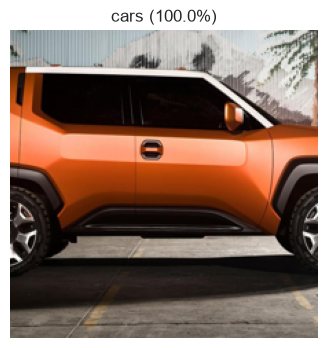

  cars         99.99%
  ship          0.01%
  airplanes     0.00%


('cars', 0.9998860359191895)

In [22]:
model.save("vehicle_classifier_effnetb0.keras")
with open("class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f)
print("saved vehicle_classifier_effnetb0.keras and class_names.json")

# --- reload and predict on an arbitrary image path ---
def predict_image(image_path, model=model, class_names=CLASS_NAMES, show=True):
    img = Image.open(image_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    arr = np.asarray(img, dtype="float32")[None, ...]   # 0-255, no rescaling
    proba = model.predict(arr, verbose=0)[0]
    idx = int(proba.argmax())
    if show:
        plt.figure(figsize=(4, 4))
        plt.imshow(img); plt.axis("off")
        plt.title(f"{class_names[idx]} ({proba[idx]:.1%})")
        plt.show()
        for c, p in sorted(zip(class_names, proba), key=lambda t: -t[1]):
            print(f"  {c:12s} {p:6.2%}")
    return class_names[idx], float(proba[idx])

# demo on one test image
predict_image(p_test[0])

## Next steps

- **More data.** 16 images per class is the binding constraint. A few hundred per class would
  let you fine-tune deeper into the backbone and trust the numbers.
- **Fix the resolution confound.** Re-source the ship images at the same resolution as airplanes
  and cars, or downsample every class to a common size before training.
- **Try a bigger backbone** once the data supports it: `EfficientNetB3` at `IMG_SIZE=300`, or
  `ConvNeXtTiny`. Only the `build_model` cell changes.
- **Add classes.** The pipeline reads classes from folder names, so dropping in a
  `vehicles/motorcycles/` folder needs no code changes.